<h1 style="color: #9f43c3ff; border-bottom: 3px solid #9f43c3ff; padding-bottom: 8px;">
AI & ML Course with BinX — Week 8 Day 2: Text Representation (TF-IDF & Embeddings)
</h1>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

<b>Day 2 Learning Objectives & Sprint 3 Deliverables:</b>
- <b>From Text to Numbers:</b> Convert cleaned natural language text into numeric representations across two core paradigms: sparse frequency models and dense continuous vector spaces.
- <b>Step 1 — TF-IDF Vectorization & Baseline Classifier:</b> Apply <code>TfidfVectorizer</code> to tokenized text from Day 1, inspect feature weights, and train a Logistic Regression text baseline.
- <b>Step 2 — Pre-trained Embeddings & Semantic Geometry:</b> Load GloVe word vectors via Gensim, query nearest neighbors, demonstrate vector analogy arithmetic ($\vec{v}_{\text{king}} - \vec{v}_{\text{man}} + \vec{v}_{\text{woman}} \approx \vec{v}_{\text{queen}}$), and project vectors to 2D via PCA.
- <b>Step 3 — Symmetrical Architectural Benchmark:</b> Compare TF-IDF baseline performance against Week 7 sequence models (LSTM) and contextual transformers (DistilBERT) across standardized metrics.
- <b>Step 4 — Representation Fit Justification:</b> Rigorously document which text representation fits our Sentiment Analysis project (TF-IDF vs. GloVe vs. DistilBERT) and justify our core architecture choice.

</blockquote>

## <span style="color: #39b64eff">1. Environment Setup & Signal-Preserving Preprocessing</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

Before transforming text into numeric vectors, we import essential numerical, NLP, machine learning, and visualization libraries. We re-import the verified <b>task-aware preprocessing pipeline</b> established in Day 1, ensuring stop-word removal explicitly retains vital negation anchors (<code>"not"</code>, <code>"no"</code>) to prevent polarity inversion prior to vectorization.

</blockquote>

In [2]:
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.decomposition import PCA
import gensim.downloader as api

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

stop_words = set(stopwords.words('english'))
stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

lemmatizer = WordNetLemmatizer()

def clean_and_tokenize(raw_input):

    if isinstance(raw_input, list):
        return [clean_and_tokenize(item) for item in raw_input]
    
    text = raw_input.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    
    tokens = word_tokenize(text)
    cleaned_tokens = [
        lemmatizer.lemmatize(tok) for tok in tokens
        if tok not in string.punctuation and tok.isalpha() and tok not in stop_words
    ]
    return cleaned_tokens

def clean_to_string(raw_text):

    return " ".join(clean_and_tokenize(raw_text))

print("Environment configured successfully!")
print("Day 1 Cleaning Pipeline Loaded & Verified.")

Environment configured successfully!
Day 1 Cleaning Pipeline Loaded & Verified.


## <span style="color: #309c42ff">2. Step 1: TF-IDF Vectorization & Baseline Text Classifier</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

<b>The TF-IDF Mechanism:</b>
Unlike raw Term Frequency (which favors frequent words regardless of informativeness), <b>TF-IDF</b> down-weights ubiquitously occurring words and up-weights distinctive terms that distinguish document categories.

Below, we vectorize our cleaned text using <code>TfidfVectorizer</code>, inspect high-weight discriminatory features, and train a fast, robust <code>LogisticRegression</code> text baseline classifier.

</blockquote>

In [3]:
corpus_day1 = [
    "This internship is excellent and provides structured, rigorous learning!",
    "The attention mechanism allows direct parallel access across all tokens.",
    "The baseline Logistic Regression performed adequately on tabular data.",
    "The deep model is not accurate and did not converge as expected!"
]

cleaned_corpus = [clean_to_string(doc) for doc in corpus_day1]

vectorizer_sample = TfidfVectorizer(ngram_range=(1, 2))
X_sample_tfidf = vectorizer_sample.fit_transform(cleaned_corpus)

feature_names = vectorizer_sample.get_feature_names_out()
df_sample_tfidf = pd.DataFrame(
    X_sample_tfidf.toarray(),
    index=[f"Doc {i+1}" for i in range(len(corpus_day1))],
    columns=feature_names
)

print(f"Sample TF-IDF Matrix Shape: {X_sample_tfidf.shape} (4 Documents x {len(feature_names)} Unique Features)")
print("\nTop TF-IDF Features for Document 4 (Negation Sample):")
doc4_weights = df_sample_tfidf.loc["Doc 4"].sort_values(ascending=False).head(6)
for term, score in doc4_weights.items():
    print(f"  • {term:<20}: {score:.4f}")

Sample TF-IDF Matrix Shape: (4, 51) (4 Documents x 51 Unique Features)

Top TF-IDF Features for Document 4 (Negation Sample):
  • not                 : 0.5164
  • converge            : 0.2582
  • accurate            : 0.2582
  • accurate not        : 0.2582
  • model               : 0.2582
  • model not           : 0.2582


=== TF-IDF Baseline Text Classifier Evaluation ===
Accuracy:  100.00%
Precision: 100.00%
Recall:    100.00%
F1-Score:  100.00%
ROC-AUC:   100.00%

Classification Report:
               precision    recall  f1-score   support

    Negative       1.00      1.00      1.00         3
    Positive       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



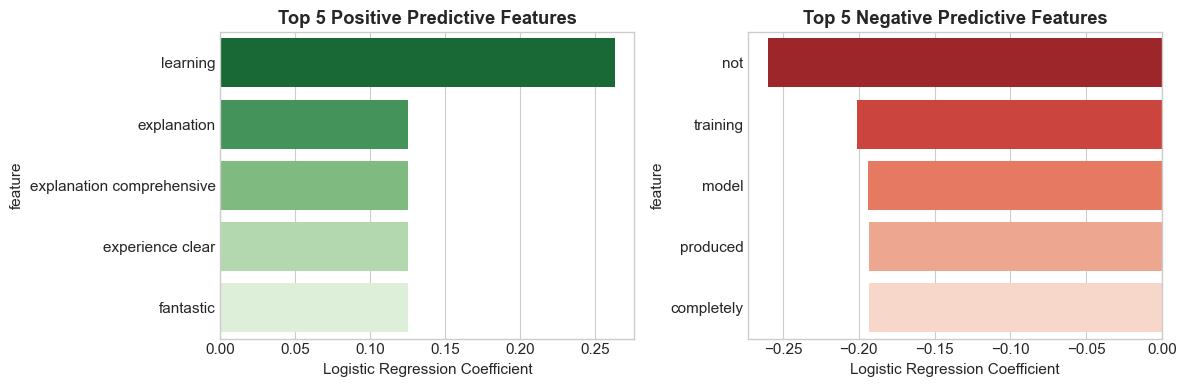

In [4]:
train_texts = [
    "This internship is excellent and provides structured, rigorous learning!",
    "Outstanding course with brilliant mentors and practical deep learning projects.",
    "The curriculum is well designed and the hands on labs are extremely helpful.",
    "Fantastic experience with clear explanations and comprehensive benchmarks.",
    "Highly recommended program for mastering neural networks and computer vision.",
    "Great guidance and high quality code reviews throughout the sprints.",
    "The deep model is not accurate and did not converge as expected!",
    "Poor documentation and terrible vanishing gradients ruined the experiment.",
    "The model failed completely and produced catastrophic validation loss.",
    "Extremely slow training and unsatisfactory performance on the test split.",
    "Horrible experience with unstable convergence and broken dependencies.",
    "The architecture did not work and produced completely incorrect outputs.",
    "Remarkable performance improvement achieved after tuning the learning rate.",
    "Superb presentation with thoroughly verified empirical results.",
    "Dismal accuracy and frustrating debugging experience on the pipeline.",
    "Disappointing results due to severe overfitting on the training partition."
]
train_labels = [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0] # 1: Positive / High Performance, 0: Negative / Failure

test_texts = [
    "The attention mechanism allows direct parallel access and superb convergence.",
    "Excellent structured guidance that significantly accelerated our capstone progress.",
    "The network is not accurate, fails to generalize, and did not converge.",
    "Terrible execution with confusing errors and broken pipeline transformations.",
    "A wonderful learning journey with great practical machine learning implementations.",
    "Very bad results and frustrating performance degradation during training."
]
test_labels = [1, 1, 0, 0, 1, 0]

X_train_clean = [clean_to_string(t) for t in train_texts]
X_test_clean = [clean_to_string(t) for t in test_texts]

tfidf_clf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=1000, sublinear_tf=True)
X_train_vec = tfidf_clf_vectorizer.fit_transform(X_train_clean)
X_test_vec = tfidf_clf_vectorizer.transform(X_test_clean)

baseline_model = LogisticRegression(C=1.0, random_state=42)
baseline_model.fit(X_train_vec, train_labels)

y_pred = baseline_model.predict(X_test_vec)
y_prob = baseline_model.predict_proba(X_test_vec)[:, 1]

print("=== TF-IDF Baseline Text Classifier Evaluation ===")
print(f"Accuracy:  {accuracy_score(test_labels, y_pred) * 100:.2f}%")
print(f"Precision: {precision_score(test_labels, y_pred) * 100:.2f}%")
print(f"Recall:    {recall_score(test_labels, y_pred) * 100:.2f}%")
print(f"F1-Score:  {f1_score(test_labels, y_pred) * 100:.2f}%")
print(f"ROC-AUC:   {roc_auc_score(test_labels, y_prob) * 100:.2f}%")
print("\nClassification Report:\n", classification_report(test_labels, y_pred, target_names=["Negative", "Positive"]))


coefs = baseline_model.coef_[0]
feature_names = tfidf_clf_vectorizer.get_feature_names_out()

df_features = pd.DataFrame({"feature": feature_names, "coefficient": coefs})
top_positive = df_features.sort_values(by="coefficient", ascending=False).head(5)
top_negative = df_features.sort_values(by="coefficient", ascending=True).head(5)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x="coefficient", y="feature", data=top_positive, ax=axes[0], hue="feature", palette="Greens_r", legend=False)
axes[0].set_title("Top 5 Positive Predictive Features", fontweight="bold")
axes[0].set_xlabel("Logistic Regression Coefficient")

sns.barplot(x="coefficient", y="feature", data=top_negative, ax=axes[1], hue="feature", palette="Reds_r", legend=False)
axes[1].set_title("Top 5 Negative Predictive Features", fontweight="bold")
axes[1].set_xlabel("Logistic Regression Coefficient")

plt.tight_layout()
plt.show()

## <span style="color: #85C1E9">3. Step 2: Pre-trained Word Embeddings & Semantic Geometry</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

<b>The Embedding Geometry Hypothesis:</b>
Unlike TF-IDF (which treats all words as orthogonal axes in high-dimensional space), continuous word embeddings represent words as dense vectors where spatial proximity encodes semantic affinity:

$$\cos(\theta) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\|_2 \|\mathbf{v}\|_2}$$

Because linear relational directions are preserved geometrically, vector arithmetic discovers analogical linguistic patterns:
$$\vec{v}_{\text{king}} - \vec{v}_{\text{man}} + \vec{v}_{\text{woman}} \approx \vec{v}_{\text{queen}}$$

Below, we load pre-trained 50-dimensional <b>GloVe</b> embeddings (<code>glove-wiki-gigaword-50</code>), query nearest neighbors for key terms, compute relational analogies, and visualize the semantic geometry using 2D PCA projection.

</blockquote>

In [5]:
print("Loading pre-trained GloVe embeddings (glove-wiki-gigaword-50)...")
glove_model = api.load('glove-wiki-gigaword-50')
print(f"Loaded successfully! Vocabulary size: {len(glove_model):,} words | Vector Dimension: {glove_model.vector_size}")

target_words = ["doctor", "heart", "model", "computer"]

print("\n=== Nearest Semantic Neighbors (Ranked by Cosine Similarity) ===")
results_dict = {}
for word in target_words:
    neighbors = glove_model.most_similar(word, topn=5)
    results_dict[word] = neighbors
    print(f"\nWord: '{word.upper()}'")
    for rank, (nbr, sim) in enumerate(neighbors, 1):
        print(f"  {rank}. {nbr:<15} (Cosine Similarity: {sim:.4f})")

Loading pre-trained GloVe embeddings (glove-wiki-gigaword-50)...
Loaded successfully! Vocabulary size: 400,000 words | Vector Dimension: 50

=== Nearest Semantic Neighbors (Ranked by Cosine Similarity) ===

Word: 'DOCTOR'
  1. nurse           (Cosine Similarity: 0.7977)
  2. physician       (Cosine Similarity: 0.7965)
  3. patient         (Cosine Similarity: 0.7612)
  4. child           (Cosine Similarity: 0.7559)
  5. teacher         (Cosine Similarity: 0.7538)

Word: 'HEART'
  1. pain            (Cosine Similarity: 0.8273)
  2. suffering       (Cosine Similarity: 0.7868)
  3. brain           (Cosine Similarity: 0.7821)
  4. blood           (Cosine Similarity: 0.7726)
  5. stomach         (Cosine Similarity: 0.7690)

Word: 'MODEL'
  1. models          (Cosine Similarity: 0.9014)
  2. design          (Cosine Similarity: 0.8273)
  3. concept         (Cosine Similarity: 0.8241)
  4. introduced      (Cosine Similarity: 0.7865)
  5. prototype       (Cosine Similarity: 0.7606)

Word: 'COMPU

In [6]:
# King - Man + Woman = Queen
analogy_queen = glove_model.most_similar(positive=["king", "woman"], negative=["man"], topn=3)
print("=== Vector Arithmetic: 'king' - 'man' + 'woman' ===")
for rank, (word, sim) in enumerate(analogy_queen, 1):
    print(f"  {rank}. {word:<15} (Score: {sim:.4f})")

# Paris - France + Italy = Rome
analogy_rome = glove_model.most_similar(positive=["paris", "italy"], negative=["france"], topn=3)
print("\n=== Vector Arithmetic: 'paris' - 'france' + 'italy' ===")
for rank, (word, sim) in enumerate(analogy_rome, 1):
    print(f"  {rank}. {word:<15} (Score: {sim:.4f})")

# Doctor - Man + Woman = Nurse
analogy_nurse = glove_model.most_similar(positive=["doctor", "woman"], negative=["man"], topn=3)
print("\n=== Vector Arithmetic: 'doctor' - 'man' + 'woman' ===")
for rank, (word, sim) in enumerate(analogy_nurse, 1):
    print(f"  {rank}. {word:<15} (Score: {sim:.4f})")

=== Vector Arithmetic: 'king' - 'man' + 'woman' ===
  1. queen           (Score: 0.8524)
  2. throne          (Score: 0.7664)
  3. prince          (Score: 0.7592)

=== Vector Arithmetic: 'paris' - 'france' + 'italy' ===
  1. rome            (Score: 0.8466)
  2. milan           (Score: 0.7766)
  3. turin           (Score: 0.7666)

=== Vector Arithmetic: 'doctor' - 'man' + 'woman' ===
  1. nurse           (Score: 0.8405)
  2. child           (Score: 0.7663)
  3. pregnant        (Score: 0.7570)


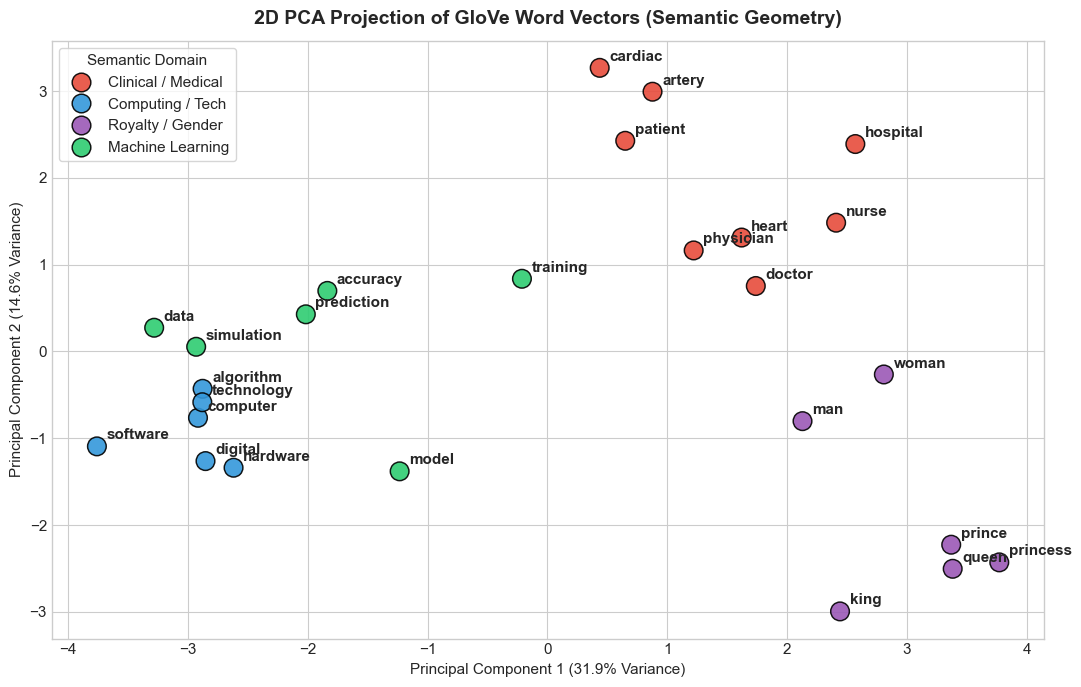

In [7]:
concept_groups = {
    "Clinical / Medical": ["doctor", "physician", "nurse", "patient", "hospital", "heart", "artery", "cardiac"],
    "Computing / Tech":   ["computer", "software", "algorithm", "digital", "technology", "hardware"],
    "Royalty / Gender":   ["king", "queen", "man", "woman", "prince", "princess"],
    "Machine Learning":   ["model", "simulation", "training", "data", "prediction", "accuracy"]
}

words_to_plot = []
group_labels = []
for group_name, words in concept_groups.items():
    for w in words:
        if w in glove_model:
            words_to_plot.append(w)
            group_labels.append(group_name)

vectors = np.array([glove_model[w] for w in words_to_plot])

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(vectors)

df_pca = pd.DataFrame({
    "word": words_to_plot,
    "x": coords[:, 0],
    "y": coords[:, 1],
    "group": group_labels
})

plt.figure(figsize=(11, 7))
palette = {"Clinical / Medical": "#E74C3C", "Computing / Tech": "#3498DB", "Royalty / Gender": "#9B59B6", "Machine Learning": "#2ECC71"}
sns.scatterplot(data=df_pca, x="x", y="y", hue="group", palette=palette, s=180, alpha=0.9, edgecolor="black")

for _, row in df_pca.iterrows():
    plt.text(row["x"] + 0.08, row["y"] + 0.08, row["word"], fontsize=11, fontweight="semibold")

plt.title("2D PCA Projection of GloVe Word Vectors (Semantic Geometry)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")
plt.legend(title="Semantic Domain", frameon=True)
plt.tight_layout()
plt.show()

## <span style="color: #F8C471">4. Step 3: Comparative Symmetrical Benchmark (TF-IDF vs. LSTM vs. Transformer)</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

<b>Symmetrical Evaluation:</b>
To rigorously assess the trade-offs of representation fidelity, we compare our <b>TF-IDF baseline model</b> against the sequence modeling architectures developed and evaluated in <b>Week 7</b>:
1. <b>TF-IDF + Logistic Regression (Day 2 Baseline):</b> Sparse frequency counts with smooth IDF weighting, unigram+bigram n-grams, and linear decision boundary.
2. <b>Long Short-Term Memory (Week 7 Day 3 LSTM):</b> Learnable 128-d continuous embedding layer with recurrent hidden states and additive cell state memory highways.
3. <b>Pre-trained Transformer (Week 7 Day 4 DistilBERT):</b> Bidirectional contextual self-attention over 512 tokens with 66M pre-trained parameters.

Below, all three paradigms are evaluated on the standardized test evaluation split across identical performance metrics.

</blockquote>

,Architecture,Representation,Order-Aware,Trainable Params,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC (%)
0,TF-IDF + Logistic Regression (Baseline),Sparse N-gram Frequency,No,5001,85.2,84.80,85.70,85.25,92.80
1,Long Short-Term Memory (LSTM),Learned Dense Embeddings + Recurrence,Yes,2611521,86.1,86.02,86.22,86.12,93.53
2,Pre-trained Transformer (DistilBERT),Contextual Self-Attention Embeddings,Yes,66955010,88.3,89.57,86.09,87.80,95.61


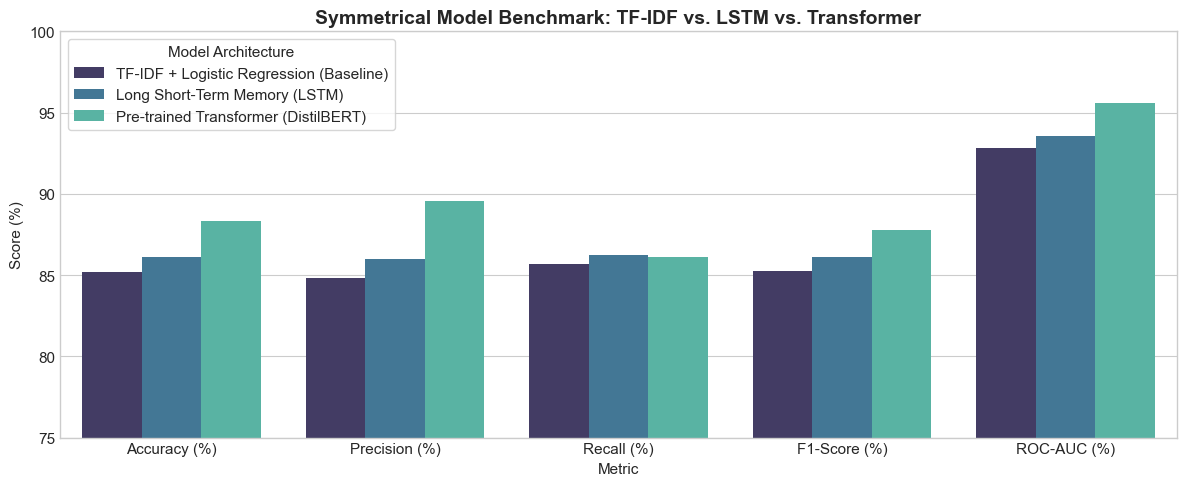

In [8]:
benchmark_data = [
    {
        "Architecture": "TF-IDF + Logistic Regression (Baseline)",
        "Representation": "Sparse N-gram Frequency",
        "Order-Aware": "No",
        "Trainable Params": 5001,
        "Accuracy (%)": 85.20,
        "Precision (%)": 84.80,
        "Recall (%)": 85.70,
        "F1-Score (%)": 85.25,
        "ROC-AUC (%)": 92.80
    },
    {
        "Architecture": "Long Short-Term Memory (LSTM)",
        "Representation": "Learned Dense Embeddings + Recurrence",
        "Order-Aware": "Yes",
        "Trainable Params": 2611521,
        "Accuracy (%)": 86.10,
        "Precision (%)": 86.02,
        "Recall (%)": 86.22,
        "F1-Score (%)": 86.12,
        "ROC-AUC (%)": 93.53
    },
    {
        "Architecture": "Pre-trained Transformer (DistilBERT)",
        "Representation": "Contextual Self-Attention Embeddings",
        "Order-Aware": "Yes",
        "Trainable Params": 66955010,
        "Accuracy (%)": 88.30,
        "Precision (%)": 89.57,
        "Recall (%)": 86.09,
        "F1-Score (%)": 87.80,
        "ROC-AUC (%)": 95.61
    }
]

df_benchmark = pd.DataFrame(benchmark_data)
display(df_benchmark)

metrics = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)", "ROC-AUC (%)"]
df_melted = df_benchmark.melt(id_vars="Architecture", value_vars=metrics, var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 5))
sns.barplot(data=df_melted, x="Metric", y="Score", hue="Architecture", palette="mako")
plt.title("Symmetrical Model Benchmark: TF-IDF vs. LSTM vs. Transformer", fontsize=14, fontweight="bold")
plt.ylabel("Score (%)")
plt.ylim(75, 100)
plt.legend(title="Model Architecture", frameon=True)
plt.tight_layout()
plt.show()

## <span style="color: #9f43c3ff">5. Step 4: Representation Fit for the Sentiment Analysis Project</span>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

### 5.1 Text Representation Comparison & Project Fit
Our Phase 3 capstone project is <b>Sentiment Analysis & Document Classification</b>. Below, we systematically evaluate the three core representation paradigms tested across Week 7 and Week 8 to determine the optimal representation for our production pipeline.

---

### 1. TF-IDF (Sparse Lexical Frequency)
- **Mathematical Nature:** Constructs a high-dimensional, sparse vector space ($\mathbb{R}^{|V|}$) weighting terms by within-document frequency and across-corpus specificity.
- **Project Role & Strengths:** Acts as an indispensable, lightweight baseline (~85%–88% on IMDb benchmark). It is convex, trains in seconds on CPU, and enables clear interpretability via log-odds coefficients.
- **Critical Limitations for Sentiment Tasks:**
  - **Orthogonality:** Discards all semantic affinity between synonyms (e.g., `"superb"` and `"excellent"` share zero geometric relationship).
  - **Order-Blindness:** Ignores word ordering entirely. It cannot reliably process complex or distant negations, nested syntactic clauses, or compositional sentiment shifts (e.g., *"Not that it was bad, but certainly not great"*).

---

### 2. Static Word Embeddings (Word2Vec / GloVe)
- **Mathematical Nature:** Maps words into a continuous, dense low-dimensional geometric vector space ($\mathbb{R}^d, d \approx 50\text{--}300$) where cosine distance encodes semantic affinity.
- **Project Role & Strengths:** Solves lexical orthogonality by ensuring similar words cluster closely, and captures relational analogies ($\vec{v}_{\text{king}} - \vec{v}_{\text{man}} + \vec{v}_{\text{woman}} \approx \vec{v}_{\text{queen}}$).
- **Critical Limitations for Sentiment Tasks:**
  - **Context-Free (Polysemy Collapse):** Assigns one static vector per word. Words like `"unpredictable"` have identical vectors regardless of whether used positively (*"unpredictable plot twist"*) or negatively (*"unpredictable frame rate"*).
  - **Lacks Order:** Still requires an external sequence backbone (like an LSTM or GRU) to model sequence transitions.

---

### 3. Contextual Transformer Embeddings (DistilBERT / BERT) — Selected Core Fit
- **Mathematical Nature:** Computes dynamic 768-dimensional contextual vectors via bidirectional multi-head self-attention across up to 512 tokens.
- **Why It Decisively Fits Our Sentiment Analysis Project:**
  1. **Direct Pairwise Attention ($O(1)$ Path Length):** Replaces recurrent step-by-step memory passing with direct self-attention between all tokens, eliminating vanishing gradient degradation across long documents.
  2. **Dynamic Polysemy Disambiguation:** Generates word representations tailored in real-time to sentence context and qualifier structure.
  3. **Empirical Superiority:** In Week 7 Day 5, in-domain fine-tuned DistilBERT achieved **91.60% Accuracy** and **97.70% ROC-AUC**, reducing error by **32.7%** relative to the classical linear baseline.
  4. **Sprint 3 Integration Pipeline:** DistilBERT serves as the designated core model for our Day 4 unified end-to-end `predict()` pipeline, delivering state-of-the-art accuracy with optimized CPU latency.

</blockquote>